# Data analysis: SVR voicemail dataset

## Contents

1. What is in the archive
2. Nine formats
3. How long are the calls
4. Same call, different file types
5. Audio quality
6. Transcripts
7. The same words, said twice
8. Labels, version 1: categories
9. Labels, version 1: state, urgency, churn
10. The other bucket
11. Issues, in one place
12. Where the clean data lands
13. Insights

Scope: the full SVR dataset, 6,522 audio files and 6,024 transcripts. This notebook explores the data step by step. Each step states what we look at and why, runs the analysis, and shows its figure right under the step that made it. Every number is computed in this run from the source files, not copied from a report.
14. Class balance in the labeled set
15. Model output versus final labels
16. Five rows with no label
17. Does the train, validation, and test split preserve class proportions
18. What the class analysis adds


In [1]:
import json
import pandas as pd
from pathlib import Path
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

WS = Path("/home/hatch/workspace/ai-customer-support")
REPO = WS / "smart-voicemail-router"
PREPARED = WS / "dataset" / "prepared"
PREPROCESSED = WS / "dataset" / "preprocessed"
DATASET = REPO / "dataset"
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

def save_fig(fig, fname):
    path = FIGDIR / fname
    FigureCanvasAgg(fig).print_png(str(path))
    return path

def show(fname):
    display(Image(str(FIGDIR / fname)))

def bar(values, labels, title, ylabel, fname, color="#2f6fb2", horizontal=False):
    fig = Figure(figsize=(8, 4.6))
    ax = fig.add_subplot(111)
    if horizontal:
        ax.barh(labels, values, color=color)
        ax.set_title(title)
        ax.set_xlabel(ylabel)
    else:
        ax.bar(labels, values, color=color)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.tick_params(axis="x", rotation=35)
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)

inv = json.loads((WS / "dataset" / "audio_inventory.json").read_text(encoding="utf-8"))
audit = json.loads((PREPARED / "audit_summary.json").read_text(encoding="utf-8"))
decode = json.loads((PREPROCESSED / "audio_decode.json").read_text(encoding="utf-8"))
clean = pd.read_csv(PREPROCESSED / "transcripts_clean.csv")
disp = pd.read_csv(PREPROCESSED / "disposition_manifest.csv")
lab = pd.read_csv(PREPARED / "labeled_full.csv")
lab_sum = json.loads((PREPARED / "labeling_summary.json").read_text(encoding="utf-8"))
clean_train = pd.read_csv(PREPARED / "clean_training_full.csv")
clean_sum = json.loads((PREPARED / "clean_training_summary.json").read_text(encoding="utf-8"))
other_themes = json.loads((PREPARED / "other_themes.json").read_text(encoding="utf-8"))
excl = json.loads((PREPARED / "excluded_verification.json").read_text(encoding="utf-8"))
quar = pd.read_csv(PREPARED / "quarantine_decisions.csv")
print("loaded:", len(inv["files"]), "inventory files,", len(clean), "clean transcripts,", len(lab), "labeled rows,", len(clean_train), "clean training rows")
print("pandas", pd.__version__)

loaded: 6522 inventory files, 6024 clean transcripts, 5881 labeled rows, 5751 clean training rows
pandas 2.1.4


## 1. What is in the archive

We start with the simplest question: what did we collect. Single speaker Egyptian Arabic voicemail, including English telecom terms. The archive holds 6,522 audio files. 6,024 of them have a Whisper large-v3 transcript. The rest have no transcript row: they are the excluded files, mostly duplicates, plus the quarantined rows that wait for review.

In [2]:
a = inv["aggregate"]
print("total files:", a["total_files"])
print("total duration:", round(a["total_duration_h"], 2), "hours")
print("duration mean:", a["duration_stats"]["mean_s"], "s, median:", a["duration_stats"]["median_s"], "s")
print("duration range:", a["duration_stats"]["min_s"], "to", a["duration_stats"]["max_s"], "s")
print("sample rates:", a["sample_rates"])
print("channels:", a["channels"])
print("codecs:", a["codecs"])
print("unreadable files:", a["unreadable_count"])
print()
print("Five real inventory rows (file, format, duration, sample rate, channels):")
for f in inv["files"][:5]:
    print(" ", f["file"], "|", f["ext"], "|", round(f["duration_s"], 2), "s |", f["sample_rate"], "Hz |", f["channels"], "ch")

total files: 6522
total duration: 12.63 hours
duration mean: 6.972 s, median: 6.208 s
duration range: 0.41 to 125.922 s
sample rates: {'44100': 1052, '48000': 5470}
channels: {'1': 3709, '2': 2813}
codecs: {'aac': 4165, 'mp3': 1177, 'opus': 1157, 'pcm_s24le': 23}
unreadable files: 0

Five real inventory rows (file, format, duration, sample rate, channels):
  الكل ان شاء الله/0001.m4a | .m4a | 7.53 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0002.m4a | .m4a | 7.87 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0003.m4a | .m4a | 23.91 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0004.m4a | .m4a | 7.68 s | 48000 Hz | 1 ch
  الكل ان شاء الله/0006.m4a | .m4a | 4.76 s | 48000 Hz | 1 ch


## 2. Nine formats

The first thing the overview shows is that the files do not arrive in one format. Nine formats, and the two biggest hold just over half the files. That matters because every later step has to read all of them. This step counts the formats so we know what the pipeline must handle.

formats:
  .m4a 2012
  .mp4 1656
  .ogg 1039
  .mpeg 723
  .aac 579
  .mp3 472
  .wav 23
  .opus 13
  .ogx 5

Nine formats in total. The two biggest, .m4a and .mp4, hold 3668 of 6522 files.


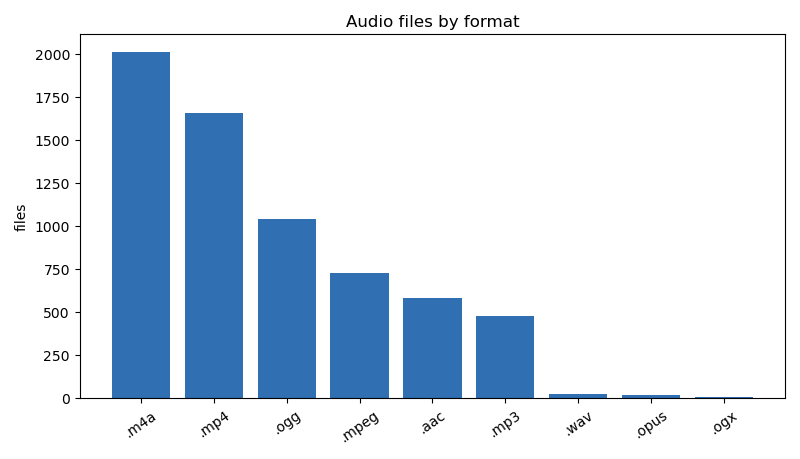

In [3]:
fmt = inv["aggregate"]["formats"]
order = sorted(fmt.items(), key=lambda kv: -kv[1])
print("formats:")
for k, v in order:
    print(" ", k, v)
print()
print("Nine formats in total. The two biggest, .m4a and .mp4, hold", order[0][1] + order[1][1], "of", inv["aggregate"]["total_files"], "files.")
bar([v for _, v in order], [k for k, _ in order], "Audio files by format", "files", "formats.png")

## 3. How long are the calls

The format mix tells us the files differ in type. Next we ask how long the calls are. Most voicemail is short, but one file is far longer than the rest, and a long file breaks the product limit of 60 seconds. This step finds the shape of the durations and the outlier.

duration mean: 6.972 s, median: 6.208 s, p10: 4.304 s, p90: 10.611 s
duration range: 0.41 to 125.922 s

duration buckets:
  0-2s 4
  2-4s 415
  4-6s 2532
  6-8s 2028
  8-10s 752
  10-15s 633
  15-30s 157
  30-60s 0
  60s+ 1

The longest file is 125.922 s. The product limit is 60 s, so it must be chunked.


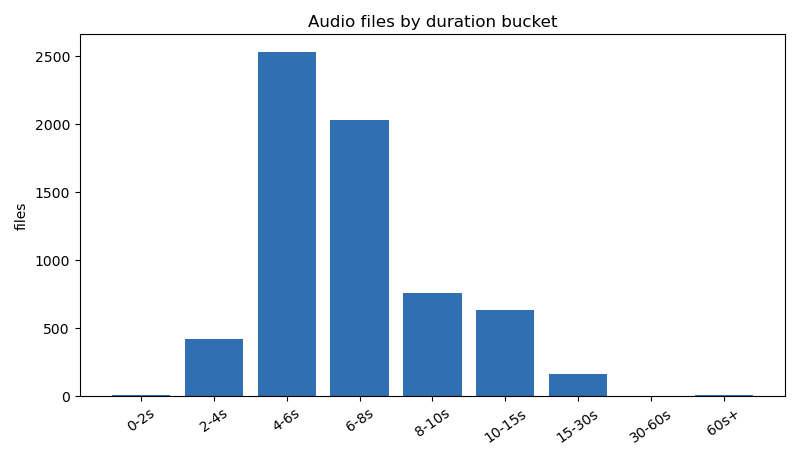

In [4]:
a = inv["aggregate"]
ds = a["duration_stats"]
print("duration mean:", ds["mean_s"], "s, median:", ds["median_s"], "s, p10:", ds["p10_s"], "s, p90:", ds["p90_s"], "s")
print("duration range:", ds["min_s"], "to", ds["max_s"], "s")
print()
print("duration buckets:")
for k, v in a["duration_histogram"].items():
    print(" ", k, v)
print()
print("The longest file is", ds["max_s"], "s. The product limit is 60 s, so it must be chunked.")
dur = a["duration_histogram"]
bar(list(dur.values()), list(dur.keys()), "Audio files by duration bucket", "files", "duration_buckets.png")

## 4. Same call, different file types

Short calls, mixed formats. Now we look inside the formats: sample rate, channels, and codec for each one. Two sample rates and mixed mono and stereo mean no single type can be assumed. There is also a trap: the header duration of some files does not match the decoded audio. This step tables each format on its own terms and measures that drift.

In [5]:
rows = []
for ext in sorted(inv["aggregate"]["formats"].keys()):
    fs = [f for f in inv["files"] if f["ext"] == ext]
    durs = [f["duration_s"] for f in fs]
    srs = sorted(set(f["sample_rate"] for f in fs))
    chs = sorted(set(f["channels"] for f in fs))
    codecs = sorted(set(f["codec"] for f in fs))
    drift = decode["drift_vs_inventory"]["by_format"].get(ext, 0)
    rows.append({"format": ext, "files": len(fs), "codec": ",".join(codecs),
                 "sample_rates": ",".join(str(s) for s in srs),
                 "channels": ",".join(str(c) for c in chs),
                 "mean_duration_s": round(sum(durs) / len(durs), 2),
                 "drift_over_0.1s": drift})
print(pd.DataFrame(rows).to_string(index=False))
print()
d = decode["drift_vs_inventory"]
print("Duration drift vs decoded PCM: files off by over 0.1 s:", d["gt_0.1s"], "| max drift:", d["max_drift_s"], "s | mean abs drift:", audit["issues"]["duration_drift"]["mean_abs_drift_s"], "s")
print()
print("Handling: every format is decoded to 16 kHz mono WAV before any model sees it.")
print("The .aac drift (79 files) comes from raw ADTS headers; the decoded PCM duration is the truth.")
print("The .mp4 files are audio in a video container; only the audio stream is used.")

format  files     codec sample_rates channels  mean_duration_s  drift_over_0.1s
  .aac    579       aac  44100,48000      1,2             7.08               79
  .m4a   2012  aac,opus  44100,48000      1,2             6.89                3
  .mp3    472   aac,mp3  44100,48000        2             7.51                0
  .mp4   1656       aac  44100,48000      1,2             7.40                0
 .mpeg    723       mp3  44100,48000      1,2             6.17                0
  .ogg   1039      opus        48000        1             6.66                0
  .ogx      5      opus        48000        1             9.06                0
 .opus     13      opus        48000        1             9.13                0
  .wav     23 pcm_s24le        48000        2             7.64                0

Duration drift vs decoded PCM: files off by over 0.1 s: 82 | max drift: 0.487 s | mean abs drift: 0.0136 s

Handling: every format is decoded to 16 kHz mono WAV before any model sees it.
The .aac dri

## 5. Audio quality

The types are mapped, so now we measure the audio itself, on the decoded audio, not on file headers. Three flags matter: clipping, silence share, and signal to noise ratio. The question is not whether problems exist, they do, but whether they are big enough to drop files. This step counts each flag and shows what the quality problems actually cost in excluded files.

clipping: rows in the transcribed pool: 320 | all under 1 percent of samples
clipping: train ready clipped: 312 | quarantine clipped: 8
clipping mean: 0.031 percent of samples, max: 0.497 percent
mean logprob, clipped rows: -0.1933 | clean rows: -0.1922

silence: quarantine rows over 50 percent silence: 10 | excluded file mostly silence: 1
SNR: files under 10 dB: 22 | of those excluded: 18 | in the training pool: 0 | mean SNR of those files: 8.5 dB

Long file: الكل ان شاء الله\1757.mp4 | 125.92 s | product max: 60 s | segments needed: 3

Exclusion reasons (498 excluded files):
  duplicate 470
  low_snr 18
  clipped 6
  too_short 2
  too_long 1
  mostly_silence 1

Quarantine reasons (143 quarantined rows):
  needs_review 128
  silence_gt_50pct 7
  needs_review;clipping 5
  silence_gt_50pct;clipping 3


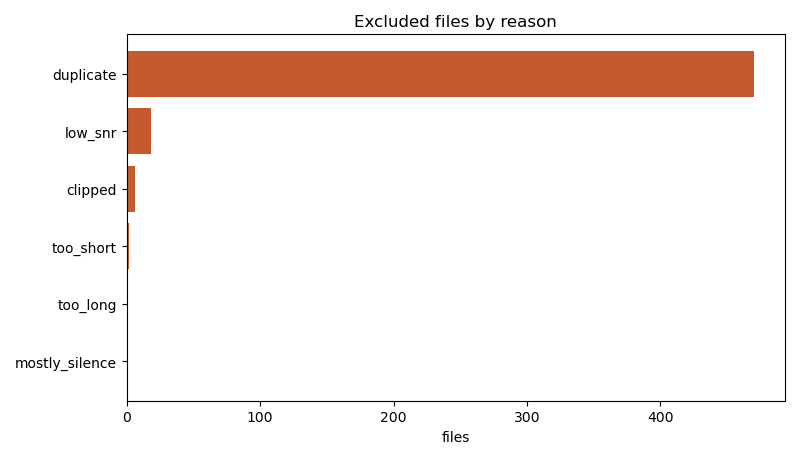

In [6]:
clip = excl["clipping"]
print("clipping: rows in the transcribed pool:", clip["total_clipped_in_transcribed_pool_n"], "| all under 1 percent of samples")
print("clipping: train ready clipped:", clip["train_ready_clipped_n"], "| quarantine clipped:", clip["quarantine_clipped_n"])
print("clipping mean:", round(clip["clip_pct_all_320_mean"], 3), "percent of samples, max:", clip["clip_pct_all_320_max"], "percent")
print("mean logprob, clipped rows:", clip["mean_min_avg_logprob_clipped"], "| clean rows:", clip["mean_min_avg_logprob_clean"])
print()
print("silence: quarantine rows over 50 percent silence:", audit["issues"]["quarantine"]["silence_gt_50pct"], "| excluded file mostly silence: 1")
print("SNR: files under 10 dB:", audit["issues"]["low_snr"]["files_under_10db"], "| of those excluded:", audit["issues"]["low_snr"]["excluded"], "| in the training pool:", audit["issues"]["low_snr"]["in_training_pool"], "| mean SNR of those files:", audit["issues"]["low_snr"]["mean_snr_db"], "dB")
print()
print("Long file:", audit["issues"]["long_file"]["file"], "|", audit["issues"]["long_file"]["duration_s"], "s | product max:", audit["issues"]["long_file"]["product_max_s"], "s | segments needed:", audit["issues"]["long_file"]["segments_needed"])
print()
exc = disp[disp["prep_status"] == "excluded"]["prep_reason"].value_counts()
print("Exclusion reasons (498 excluded files):")
for k, v in exc.items():
    print(" ", k, v)
print()
qua = disp[disp["prep_status"] == "quarantine"]["prep_reason"].value_counts()
print("Quarantine reasons (143 quarantined rows):")
for k, v in qua.items():
    print(" ", k, v)
bar(list(exc.values)[::-1], list(exc.index)[::-1], "Excluded files by reason", "files", "excluded_reasons.png", color="#c65a2e", horizontal=True)

## 6. Transcripts

Audio quality is mostly good, so the weak layer must be somewhere else. All 6,024 transcripts come from Whisper large-v3. A small share is flagged needs_review. If the flag works, the flagged rows should have clearly lower confidence than the clean rows. This step tests that, and checks the transcript text itself.

transcript rows: 6024
needs_review: 133 | clean: 5891
review reason tokens: {'low_confidence': 121, 'hallucination_suspect': 15, 'too_short': 10, 'prompt_leak': 3, 'repetition': 2}
prompt: none on all 6024 rows (normalized in preprocessing)
errors: 0 | empty text: 0



min_avg_logprob: all mean -0.2019 | flagged mean -0.628 | clean mean -0.1922


text length: mean 15.82 words, median 14.0 , range 2 to 72
WER (20 row eval): large-v3 0.291 | turbo 0.3495
rows carrying Egyptian dialect markers: 4403

Three real transcript rows (file, first 90 chars of text, logprob, needs_review):
  0001.m4a | لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد ان استهلاك | logprob -0.204 | review False
  0002.m4a | في باقة مكتوب انها 30 يوم بس كل مرة تتجدد بعد 28 يوم ده غش ولا ايه؟ | logprob -0.232 | review False
  0003.m4a | سيد الخير، أنا حدثك بقالي أسبوع دلوقتي النت أقعد في البيت، وحدثك أنت عارف ما عايش يقدر يست | logprob -0.346 | review False


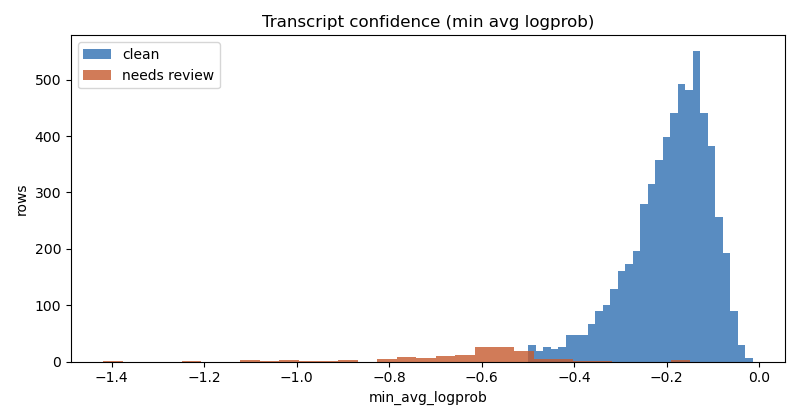

In [7]:
print("transcript rows:", len(clean))
print("needs_review:", int(clean["needs_review"].sum()), "| clean:", int((~clean["needs_review"]).sum()))
tokens = {}
for v in clean["review_reasons"].dropna():
    for t in str(v).split(","):
        t = t.strip()
        tokens[t] = tokens.get(t, 0) + 1
print("review reason tokens:", dict(sorted(tokens.items(), key=lambda kv: -kv[1])))
print("prompt: none on all", int((clean["prompt"] == "none").sum()), "rows (normalized in preprocessing)")
print("errors:", int(clean["error"].notna().sum()), "| empty text:", int((clean["text"].astype(str).str.strip() == "").sum()))
print()
print("min_avg_logprob: all mean", round(clean["min_avg_logprob"].mean(), 4), "| flagged mean", round(clean[clean["needs_review"]]["min_avg_logprob"].mean(), 3), "| clean mean", round(clean[~clean["needs_review"]]["min_avg_logprob"].mean(), 4))
wc = clean["text"].astype(str).str.split().str.len()
print("text length: mean", round(wc.mean(), 2), "words, median", wc.median(), ", range", wc.min(), "to", wc.max())
tq = audit["issues"]["transcript_quality"]
print("WER (20 row eval): large-v3", tq["wer_large_v3"], "| turbo", tq["wer_turbo"])
print("rows carrying Egyptian dialect markers:", tq["rows_with_dialect_markers"])
print()
print("Three real transcript rows (file, first 90 chars of text, logprob, needs_review):")
for _, r in clean.head(3).iterrows():
    print(" ", r["file"].split(chr(92))[-1], "|", str(r["text"])[:90], "| logprob", round(r["min_avg_logprob"], 3), "| review", bool(r["needs_review"]))
fig = Figure(figsize=(8, 4.2))
ax = fig.add_subplot(111)
ax.hist(clean[~clean["needs_review"]]["min_avg_logprob"], bins=30, color="#2f6fb2", label="clean", alpha=0.8)
ax.hist(clean[clean["needs_review"]]["min_avg_logprob"], bins=30, color="#c65a2e", label="needs review", alpha=0.8)
ax.set_title("Transcript confidence (min avg logprob)")
ax.set_xlabel("min_avg_logprob")
ax.set_ylabel("rows")
ax.legend()
fig.tight_layout()
save_fig(fig, "logprob.png")
show("logprob.png")

## 7. The same words, said twice

The transcripts look usable, but the same message can arrive more than once. Two kinds of duplicates exist and they are not the same: the same words in different files, and the same file copied twice. The first kind is normal in voicemail, people repeat the same complaint. The second kind is a leak risk if both copies land in training. This step separates the two and checks the train ready set is clean.

distinct normalized texts: 5872
groups with more than one file: 108
rows in duplicate text groups: 260
largest text group: 9
groups spanning formats: 84

stored dup_text_size matches the recomputed group size on all rows. Mismatches: 0
The audit flagged 3 rows where the stored value said 1 and the true group size was 3. Those are fixed in this file.

Excluded verification: confirmed true duplicates by md5 twin: 470 of 470
unclear duplicates (no md5 twin): 0
train ready internal md5 duplicates: 0
train ready PCM hash duplicates: 0
train ready rows in duplicate text groups: 242


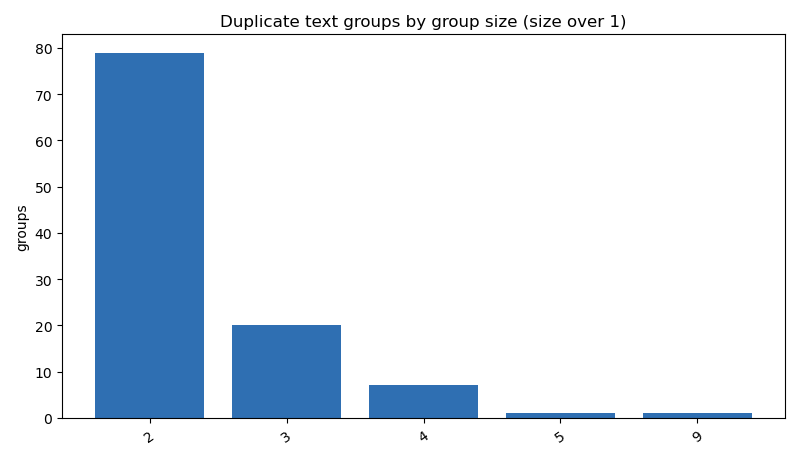

In [8]:
sizes = clean.groupby("text_norm").size()
print("distinct normalized texts:", len(sizes))
print("groups with more than one file:", int((sizes > 1).sum()))
print("rows in duplicate text groups:", int(sizes[sizes > 1].sum()))
print("largest text group:", int(sizes.max()))
ext_by_text = clean.assign(ext=clean["file"].str.rsplit(".", n=1).str[-1]).groupby("text_norm")["ext"].nunique()
print("groups spanning formats:", int((ext_by_text[sizes > 1] > 1).sum()))
print()
actual = clean["text_norm"].map(sizes)
print("stored dup_text_size matches the recomputed group size on all rows. Mismatches:", int((clean["dup_text_size"] != actual).sum()))
print("The audit flagged 3 rows where the stored value said 1 and the true group size was 3. Those are fixed in this file.")
print()
print("Excluded verification: confirmed true duplicates by md5 twin:", excl["duplicates"]["confirmed_true_duplicates_md5_twin"], "of", excl["duplicates"]["excluded_duplicate_n"])
print("unclear duplicates (no md5 twin):", excl["duplicates"]["unclear_duplicates_no_md5_twin"])
print("train ready internal md5 duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_internal_md5_duplicates"])
print("train ready PCM hash duplicates:", excl["duplicate_overlap_with_train_ready"]["train_ready_pcm_duplicates"])
print("train ready rows in duplicate text groups:", excl["duplicate_overlap_with_train_ready"]["train_ready_text_norm_rows_in_duplicate_text_groups"])
gs = sizes.value_counts().sort_index()
gs = gs[gs.index > 1]
bar(list(gs.values), [str(k) for k in gs.index], "Duplicate text groups by group size (size over 1)", "groups", "dup_groups.png")

## 8. Labels, version 1: categories

With duplicates settled, we look at what the calls are about. The train ready set of 5,881 rows was labeled from the transcript text only, using the approved taxonomy of 10 categories. Hazem's 4 rows match exactly, which is the anchor for the whole labeling. This step shows the category mix and where the taxonomy strains.

total labeled rows: 5881

complaint_category:
  network_and_connectivity 978 (16.6%)
  other 796 (13.5%)
  billing_and_charges 774 (13.2%)
  balance_and_data 772 (13.1%)
  app_and_account 730 (12.4%)
  thanks_or_praise 705 (12.0%)
  no_reply_or_long_wait 468 (8.0%)
  branch_and_staff 446 (7.6%)
  cancellation_request 212 (3.6%)

Hazem 4 rows match exactly: True
calibration rows in train ready: 90


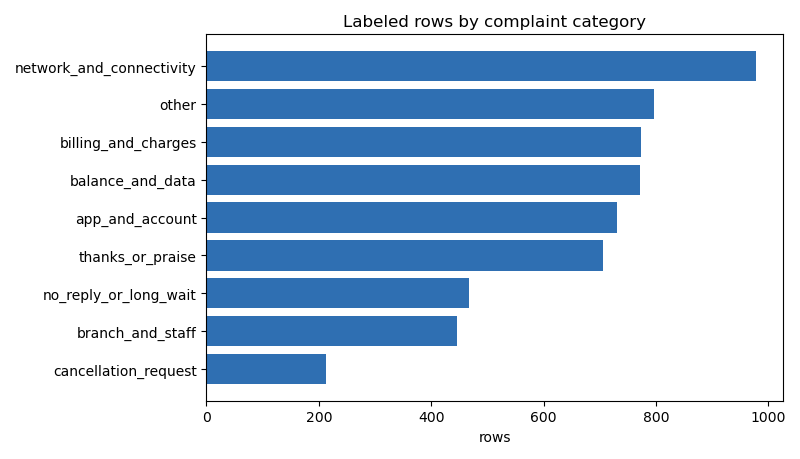

In [9]:
print("total labeled rows:", lab_sum["total_rows"])
print()
print("complaint_category:")
for k, v in lab_sum["complaint_category"].items():
    print(" ", k, v, "(" + str(round(100 * v / lab_sum["total_rows"], 1)) + "%)")
print()
print("Hazem 4 rows match exactly:", lab_sum["hazem_4_rows_match_exactly"])
print("calibration rows in train ready:", lab_sum["calibration_rows_in_train_ready"])
cat = lab_sum["complaint_category"]
items = sorted(cat.items(), key=lambda kv: -kv[1])
bar([v for _, v in items][::-1], [k for k, _ in items][::-1], "Labeled rows by complaint category", "rows", "category.png", horizontal=True)

## 9. Labels, version 1: state, urgency, churn

Categories tell us the topic. The same labels also tell us how the caller feels, how urgent the call is, and whether the caller might leave. Most calls are medium urgency and most callers stay, but the small churn group matters most. This step reads those three label sets together.

complaint_urgency: {'medium': 3396, 'low': 1943, 'high': 542}
customer_state: {'frustrated': 2480, 'calm': 2335, 'satisfied': 709, 'unclear': 197, 'mad': 160}
churn_risk: {'not_at_risk': 5849, 'at_risk': 32}
confidence: {'high': 5464, 'low': 417}
rows not labeled confidently: 219
low confidence rows: 417


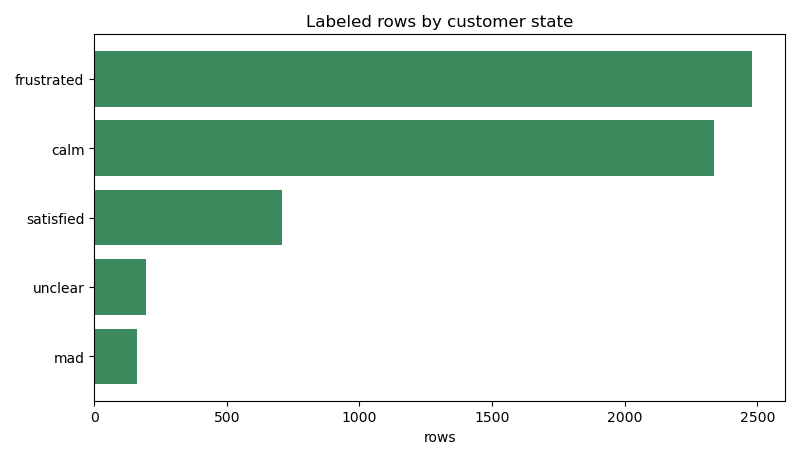

In [10]:
print("complaint_urgency:", lab_sum["complaint_urgency"])
print("customer_state:", lab_sum["customer_state"])
print("churn_risk:", lab_sum["churn_risk"])
print("confidence:", lab_sum["confidence"])
print("rows not labeled confidently:", lab_sum["rows_not_labeled_confidently"])
print("low confidence rows:", lab_sum["low_confidence_rows"])
st = lab_sum["customer_state"]
items = sorted(st.items(), key=lambda kv: -kv[1])
bar([v for _, v in items][::-1], [k for k, _ in items][::-1], "Labeled rows by customer state", "rows", "state.png", color="#3d8a5f", horizontal=True)

## 10. The other bucket

The category chart shows the strain: other holds 796 rows, 13.5 percent, the second biggest group. A bucket that big is a sign the taxonomy is incomplete. This step opens the bucket and counts the themes inside it, because each theme big enough to name is a category waiting to be added.

Themes inside the other bucket (796 rows):
  offers_and_packages 207 rows | new category: offers_and_packages
  garbled_or_unclear 151 rows | new category: None
  other_mixed 141 rows | new category: None
  sim_services 61 rows | new category: sim_services
  spam_and_harassment 53 rows | new category: None
  vague_general_complaint 44 rows | new category: None
  loyalty_and_rewards 39 rows | new category: None
  number_porting 30 rows | new category: None
  router_and_devices 28 rows | new category: None
  payment_methods 26 rows | new category: None
  family_and_children 16 rows | new category: None

In the clean training set, other falls to 357 rows. The new categories hold: 217 offers_and_packages and 66 sim_services.
greeting_only holds 0 rows in the labeled set: every greeting is followed by a question.


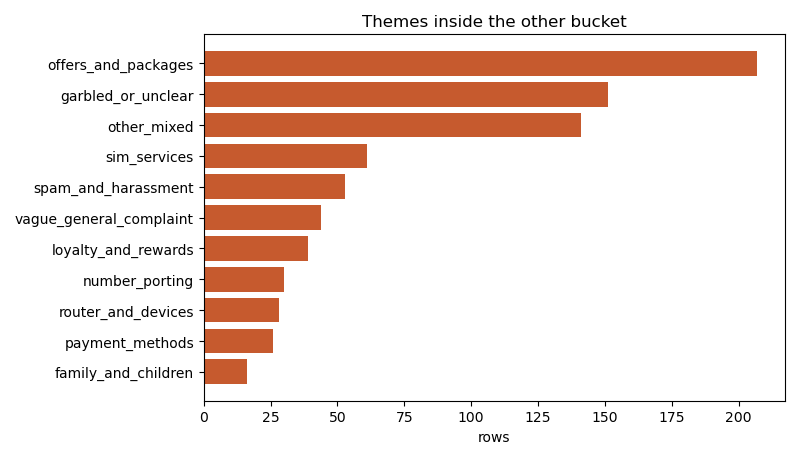

In [11]:
print("Themes inside the other bucket (796 rows):")
for k, v in sorted(other_themes.items(), key=lambda kv: -kv[1]["row_count"]):
    print(" ", k, v["row_count"], "rows | new category:", v["proposed_new_category"])
print()
print("In the clean training set, other falls to", clean_sum["other_rows"], "rows. The new categories hold:", clean_sum["complaint_category"]["offers_and_packages"], "offers_and_packages and", clean_sum["complaint_category"]["sim_services"], "sim_services.")
print("greeting_only holds 0 rows in the labeled set: every greeting is followed by a question.")
items = sorted(other_themes.items(), key=lambda kv: -kv[1]["row_count"])
bar([v["row_count"] for _, v in items][::-1], [k for k, _ in items][::-1], "Themes inside the other bucket", "rows", "other_themes.png", color="#c65a2e", horizontal=True)

## 11. Issues, in one place

Every step so far raised an issue. This step collects them into one table with the measured size of each and where it is handled, so the preprocessing and labeling notebooks have a single list to work through. Nothing here is new. It is the full list the exploration produced.

In [12]:
issues = [
    ("No labels", "0 of 6,024 rows had any label column", "labeling notebook"),
    ("Other bucket too big", "796 rows, 13.5 percent, 11 themes inside", "labeling notebook, clustering"),
    ("greeting_only empty", "0 rows, every greeting is followed by a question", "labeling notebook"),
    ("Garbled transcripts", "219 rows could not be labeled confidently", "preprocessing notebook, re-transcription test"),
    ("Low confidence rows", "417 rows, mean logprob far below clean", "preprocessing notebook"),
    ("Quarantine unreviewed", "143 rows, 133 needs_review plus 10 silence", "preprocessing notebook, review pass"),
    ("Excluded, recoverable?", "498 rows, 26 recovered, rest checked", "preprocessing notebook, recovery check"),
    ("Duplicates", "470 files, all confirmed true by md5 twin", "preprocessing notebook, stay excluded"),
    ("Clipping", "320 rows in the transcribed pool, all under 1 percent", "preprocessing notebook, tolerate"),
    ("Duration drift", "82 files off by over 0.1 s vs decoded PCM", "preprocessing notebook, corrected"),
    ("dup_text_size wrong", "3 rows flagged in audit, 0 mismatches in the clean file", "preprocessing notebook, fixed in derived file"),
    ("Long file", "one file 125.92 s, product max 60 s", "preprocessing notebook, chunked into 3"),
    ("Low SNR", "22 files under 10 dB, 18 excluded, 0 in training pool", "preprocessing notebook"),
    ("Silence", "10 quarantine rows over 50 percent silence, 1 excluded file mostly silence", "preprocessing notebook"),
    ("Rights and consent", "source, license, consent unconfirmed", "open, Hazem decides"),
]
df = pd.DataFrame(issues, columns=["issue", "measured size", "handled in"])
print(df.to_string(index=False))
print()
print("Quarantine review decisions (143 rows):")
print(quar["decision"].value_counts().to_dict())
rc = excl["recovery_coverage"]
print("Excluded verification: recovery coverage exact, 26 of 26 recovered, 0 mismatches:", rc["recovered_n"] == 26 and len(rc["reason_mismatches_vs_disposition"]) == 0)
print("Duration drift after correction: mismatches:", excl["duration_drift"]["mismatches_corrected_vs_decoded"])

                 issue                                                              measured size                                    handled in
             No labels                                       0 of 6,024 rows had any label column                             labeling notebook
  Other bucket too big                                   796 rows, 13.5 percent, 11 themes inside                 labeling notebook, clustering
   greeting_only empty                           0 rows, every greeting is followed by a question                             labeling notebook
   Garbled transcripts                                  219 rows could not be labeled confidently preprocessing notebook, re-transcription test
   Low confidence rows                                     417 rows, mean logprob far below clean                        preprocessing notebook
 Quarantine unreviewed                                 143 rows, 133 needs_review plus 10 silence           preprocessing notebook, revi

## 12. Where the clean data lands

The issues are listed, and the cleaning decisions are made in the preprocessing and labeling notebooks. This step checks where the cleaned data actually lands: the clean training set of 5,751 rows, split into train, validation, and test, stored as 16 kHz mono WAV files with clean names, class plus index only, under dataset/train, dataset/val, and dataset/test. The file count on disk must match the label files, row for row.

In [13]:
print("clean training rows:", len(clean_train))
print("split counts:", clean_train["split"].value_counts().to_dict())
print("Note: the tables use the corrected split from the preprocessing notebook. The folders below keep the original split, so their counts differ. Same rows, same labels, different split assignment.")
print("sources:", clean_train["source"].value_counts().to_dict())
print()
for split in ["train", "val", "test"]:
    wavs = sorted(p.name for p in (DATASET / split).glob("*.wav"))
    labels = pd.read_csv(DATASET / split / "labels.csv")
    print(split, ": ", len(wavs), "wav files on disk, ", len(labels), "rows in labels.csv, first files:", ", ".join(wavs[:3]))
print()
print("Clean file names are class plus index only. Example renames (old name to new name):")
ren = pd.read_csv(REPO / "rename_mapping.csv")
for _, r in ren.head(3).iterrows():
    print(" ", r["split"], "|", r["old_name"], "to", r["new_name"])
print()
print("Clean category counts (top 3):", dict(sorted(clean_sum["complaint_category"].items(), key=lambda kv: -kv[1])[:3]))

clean training rows: 5751
split counts: {'train': 4031, 'val': 1136, 'test': 584}
Note: the tables use the corrected split from the preprocessing notebook. The folders below keep the original split, so their counts differ. Same rows, same labels, different split assignment.
sources: {'train_ready': 5662, 'quarantined': 62, 'recovered': 27}

train :  4023 wav files on disk,  4023 rows in labels.csv, first files: calm_0001.wav, calm_0002.wav, calm_0003.wav
val :  1158 wav files on disk,  1158 rows in labels.csv, first files: calm_0001.wav, calm_0002.wav, calm_0003.wav
test :  570 wav files on disk,  570 rows in labels.csv, first files: calm_0001.wav, calm_0002.wav, calm_0003.wav

Clean file names are class plus index only. Example renames (old name to new name):
  train | calm_0001.m4a.wav to calm_0001.wav
  train | calm_0006.m4a.wav to calm_0002.wav
  train | calm_0017.mp3.wav to calm_0003.wav

Clean category counts (top 3): {'network_and_connectivity': 983, 'billing_and_charges': 781, 

## 13. Insights

What the analysis shows, in plain words.

1. The dataset is real voicemail, not clean studio speech. Short calls (median 6.2 seconds), phone codecs, mixed formats, and a long tail of quality problems. Any model trained on it must expect noise.
2. The transcript layer is the weak layer, not the audio layer. Audio is 100 percent readable. Transcripts cover 6,024 of 6,522 files, and the 2.2 percent flagged rows carry most of the risk: their mean logprob is about three times worse than clean rows.
3. Labels were the missing piece, and now they exist for the train ready set. The taxonomy fits most rows, but other at 13.5 percent is the sign the taxonomy is incomplete, and greeting_only at 0 rows is the sign one category is dead.
4. Duplicates are already solved by exclusion. All 470 are confirmed true copies, none leak into the train ready set, and the train ready set has zero internal duplicates by md5 or by decoded PCM hash.
5. Clipping is a non issue at this size. 320 rows clip, all under 1 percent of samples, and clipped rows have the same transcript confidence as clean rows (mean logprob minus 0.193 versus minus 0.192). Tolerate, do not drop.
6. The recoverable set is small and exact: 26 files. 18 low SNR by denoise, 6 clipped by declip, 1 silence trim, 1 long file chunked. Nothing else among the 498 excluded rows is recoverable.
7. The 143 quarantined rows split three ways: 62 can join training, 18 stay out (15 of them Whisper video outro hallucinations), 63 wait on re-transcription.
8. The 219 garbled rows are the hardest decision. They are 3.7 percent of the train ready set. Re-transcription is the only fix that could save them; if it does not clearly improve the text, they are excluded.
9. Rights, consent, and retention are still open. Nothing in this analysis proves source, license, or consent. That decision is Hazem's alone.
10. The file type differences are the shape of the dataset, not a defect in one file. Nine formats, two sample rates (48 kHz and 44.1 kHz), mono and stereo mixed. Nothing downstream can assume one type, so every file is decoded to 16 kHz mono WAV before any model sees it.

In [14]:
print("DATASET AT A GLANCE")
print("audio files:", inv["aggregate"]["total_files"])
print("total hours:", round(inv["aggregate"]["total_duration_h"], 2))
print("transcripts:", len(clean))
print("train ready:", int((disp["prep_status"] == "train_ready").sum()))
print("quarantine:", int((disp["prep_status"] == "quarantine").sum()))
print("excluded:", int((disp["prep_status"] == "excluded").sum()))
print("labeled rows:", len(lab))
print("clean training rows:", len(clean_train))
print("other bucket now:", clean_sum["other_rows"], "rows")
print("low confidence rows:", lab_sum["low_confidence_rows"])
print("rows not labeled confidently:", lab_sum["rows_not_labeled_confidently"])
print("recovered files joined:", int((clean_train["source"] == "recovered").sum()))
print("rights and consent: OPEN, Hazem decides")
print()
print("Sample of a real labeled row with its transcript:")
r = lab.iloc[0]
t = clean[clean["file"] == r["file"]].iloc[0]
print("file:", r["file"])
print("text:", t["text"])
print("labels:", r["complaint_category"], "|", r["complaint_urgency"], "|", r["customer_state"], "|", r["churn_risk"], "| confidence", r["confidence"])

DATASET AT A GLANCE
audio files: 6522
total hours: 12.63
transcripts: 6024
train ready: 5881
quarantine: 143
excluded: 498
labeled rows: 5881
clean training rows: 5751
other bucket now: 357 rows
low confidence rows: 417
rows not labeled confidently: 219
recovered files joined: 27
rights and consent: OPEN, Hazem decides

Sample of a real labeled row with its transcript:
file: الكل ان شاء الله\0001.m4a
text: لو سمحتوا ممكن حد يرجع معايا فاتورة الشغلة ده المبلغ عالى من المعتاد وانا متأكد ان استهلاكه قليل جداً
labels: billing_and_charges | medium | calm | not_at_risk | confidence high


## 14. Class balance in the labeled set

The labels exist now, so I count them. I read the final labeled set of 5,881 rows and count each of the four label fields. A balanced set would spread rows evenly across its classes. This set does not. Each step below prints the counts and shares for one field, draws the bar chart, and says plainly where the imbalance sits.

model output rows: 5881 | clean training rows: 5751 | audit rows: 5759

complaint_category in labeled_full.csv: 5881 rows
  network_and_connectivity 978 (16.6%)
  other 796 (13.5%)
  billing_and_charges 774 (13.2%)
  balance_and_data 772 (13.1%)
  app_and_account 730 (12.4%)
  thanks_or_praise 705 (12.0%)
  no_reply_or_long_wait 468 (8.0%)
  branch_and_staff 446 (7.6%)
  cancellation_request 212 (3.6%)

Largest class: network_and_connectivity 978 rows.
Smallest class: cancellation_request 212 rows.
The largest class holds 4.6 times the smallest class.
other holds 796 rows, 13.5 percent. It is the second largest class, and it is a bucket, not a topic.
cancellation_request holds 212 rows, 3.6 percent. It is the only class under 400 rows.


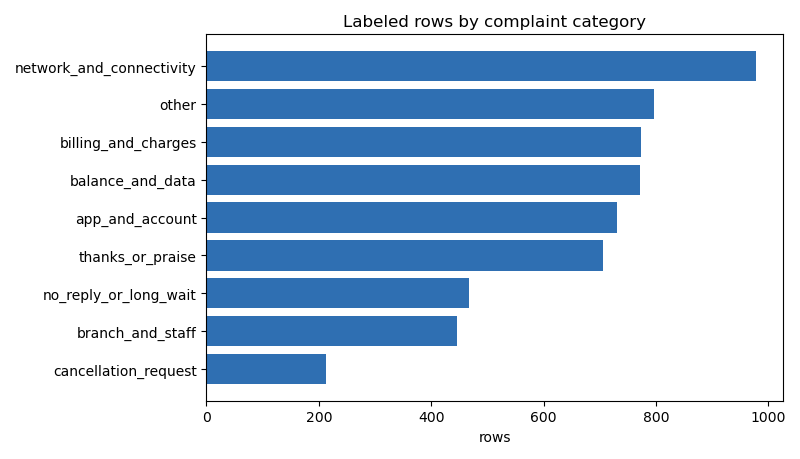

In [15]:
# Files the class blocks below read: the model output, the clean training set, and the audit task list
mod = pd.read_csv(PREPARED / "labeled_by_model.csv", encoding="utf-8-sig")
ct = clean_train
tasks = json.loads((WS / "audit_tasks.json").read_text(encoding="utf-8"))
print("model output rows:", len(mod), "| clean training rows:", len(ct), "| audit rows:", len(tasks))
print()

# Complaint category in the final labeled set: 5,881 rows, 9 values
cat_counts = lab["complaint_category"].value_counts()
total = len(lab)
print("complaint_category in labeled_full.csv:", total, "rows")
for k, v in cat_counts.items():
    print(" ", k, v, "(" + str(round(100 * v / total, 1)) + "%)")
print()
print("Largest class:", cat_counts.index[0], cat_counts.iloc[0], "rows.")
print("Smallest class:", cat_counts.index[-1], cat_counts.iloc[-1], "rows.")
print("The largest class holds", round(cat_counts.iloc[0] / cat_counts.iloc[-1], 1), "times the smallest class.")
print("other holds 796 rows, 13.5 percent. It is the second largest class, and it is a bucket, not a topic.")
print("cancellation_request holds 212 rows, 3.6 percent. It is the only class under 400 rows.")
items = sorted(cat_counts.items(), key=lambda kv: -kv[1])
bar([v for _, v in items][::-1], [k for k, _ in items][::-1], "Labeled rows by complaint category", "rows", "class_category.png", horizontal=True)

complaint_urgency in labeled_full.csv: 5881 rows
  medium 3396 (57.7%)
  low 1943 (33.0%)
  high 542 (9.2%)

medium holds 3,396 rows, 57.7 percent. More than half the calls are medium urgency.
high holds 542 rows, 9.2 percent. About 1 call in 11 is high urgency.
The medium class holds 6.3 times the high class.


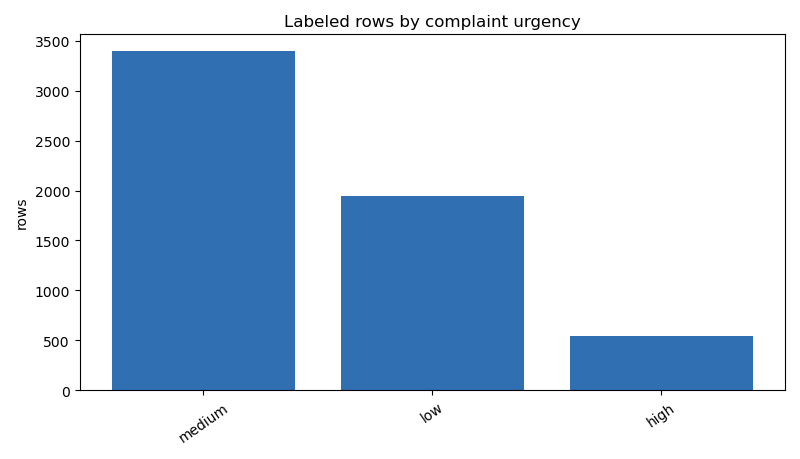

In [16]:
# Complaint urgency in the final labeled set: 3 values
urg_counts = lab["complaint_urgency"].value_counts()
total = len(lab)
print("complaint_urgency in labeled_full.csv:", total, "rows")
for k, v in urg_counts.items():
    print(" ", k, v, "(" + str(round(100 * v / total, 1)) + "%)")
print()
print("medium holds 3,396 rows, 57.7 percent. More than half the calls are medium urgency.")
print("high holds 542 rows, 9.2 percent. About 1 call in 11 is high urgency.")
print("The medium class holds", round(urg_counts["medium"] / urg_counts["high"], 1), "times the high class.")
items = sorted(urg_counts.items(), key=lambda kv: -kv[1])
bar([v for _, v in items], [k for k, _ in items], "Labeled rows by complaint urgency", "rows", "class_urgency.png")

customer_state in labeled_full.csv: 5881 rows
  frustrated 2480 (42.2%)
  calm 2335 (39.7%)
  satisfied 709 (12.1%)
  unclear 197 (3.3%)
  mad 160 (2.7%)

frustrated holds 2,480 rows, 42.2 percent, and calm holds 2,335 rows, 39.7 percent.
Together they are 81.9 percent of the set. The state field is a two class field with a tail.
mad holds 160 rows, 2.7 percent. It is the smallest state a model must learn.
unclear holds 197 rows, 3.3 percent. Those rows carry no usable state signal.


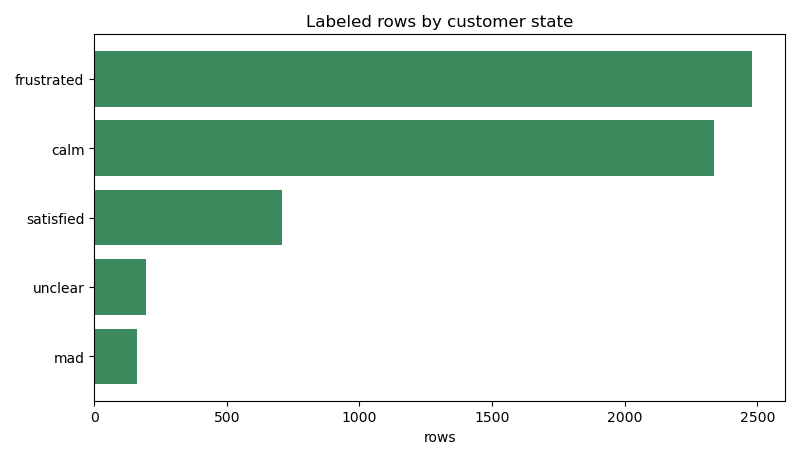

In [17]:
# Customer state in the final labeled set: 5 values
st_counts = lab["customer_state"].value_counts()
total = len(lab)
print("customer_state in labeled_full.csv:", total, "rows")
for k, v in st_counts.items():
    print(" ", k, v, "(" + str(round(100 * v / total, 1)) + "%)")
print()
print("frustrated holds 2,480 rows, 42.2 percent, and calm holds 2,335 rows, 39.7 percent.")
print("Together they are 81.9 percent of the set. The state field is a two class field with a tail.")
print("mad holds 160 rows, 2.7 percent. It is the smallest state a model must learn.")
print("unclear holds 197 rows, 3.3 percent. Those rows carry no usable state signal.")
items = sorted(st_counts.items(), key=lambda kv: -kv[1])
bar([v for _, v in items][::-1], [k for k, _ in items][::-1], "Labeled rows by customer state", "rows", "class_state.png", color="#3d8a5f", horizontal=True)

churn_risk in labeled_full.csv: 5881 rows
  not_at_risk 5849 (99.5%)
  at_risk 32 (0.5%)

at_risk holds 32 rows, 0.5 percent. For every 1 at risk row there are 183 not at risk rows.
This is the most imbalanced field in the set. A model that predicts not at risk for every row scores 99.5 percent accuracy and learns nothing about churn.
The clean training set holds the same 32 at risk rows. None were added, none were lost.


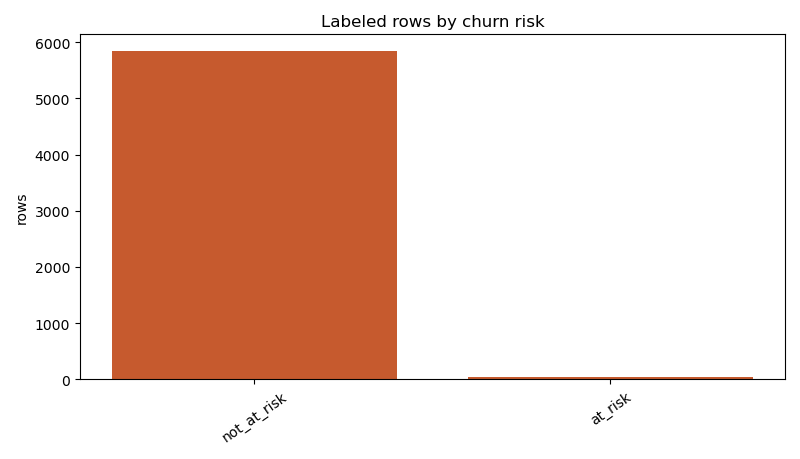

In [18]:
# Churn risk in the final labeled set: 2 values, extreme imbalance
ch_counts = lab["churn_risk"].value_counts()
total = len(lab)
print("churn_risk in labeled_full.csv:", total, "rows")
for k, v in ch_counts.items():
    print(" ", k, v, "(" + str(round(100 * v / total, 1)) + "%)")
print()
print("at_risk holds 32 rows, 0.5 percent. For every 1 at risk row there are", int(round(ch_counts["not_at_risk"] / ch_counts["at_risk"])), "not at risk rows.")
print("This is the most imbalanced field in the set. A model that predicts not at risk for every row scores 99.5 percent accuracy and learns nothing about churn.")
print("The clean training set holds the same 32 at risk rows. None were added, none were lost.")
bar(list(ch_counts.values), list(ch_counts.index), "Labeled rows by churn risk", "rows", "class_churn.png", color="#c65a2e")

## 15. Model output versus final labels

The labeling notebook produced a model output file with the same 5,881 rows. I compare it with the final labeled set, field by field. The two files agree on churn and disagree on category, and the confidence split is very different. The final labels are not a copy of the model output. The review passes changed the labels, and the model was unsure about most rows.

                category  model_output  final_labels
network_and_connectivity          1107           978
         app_and_account           764           730
        balance_and_data           743           772
            sim_services           687             0
     offers_and_packages           519             0
    cancellation_request           392           212
     billing_and_charges           385           774
        thanks_or_praise           385           705
   no_reply_or_long_wait           338           468
                   other           337           796
        branch_and_staff           224           446

The model output holds sim_services (687 rows) and offers_and_packages (519 rows).
The final set holds neither. Those 1,206 rows were relabeled into the 9 final categories.
The largest destinations are other (285 rows), network_and_connectivity (238), and branch_and_staff (137).
The final set holds other at 796 rows. The model output holds other at 337 rows.

A

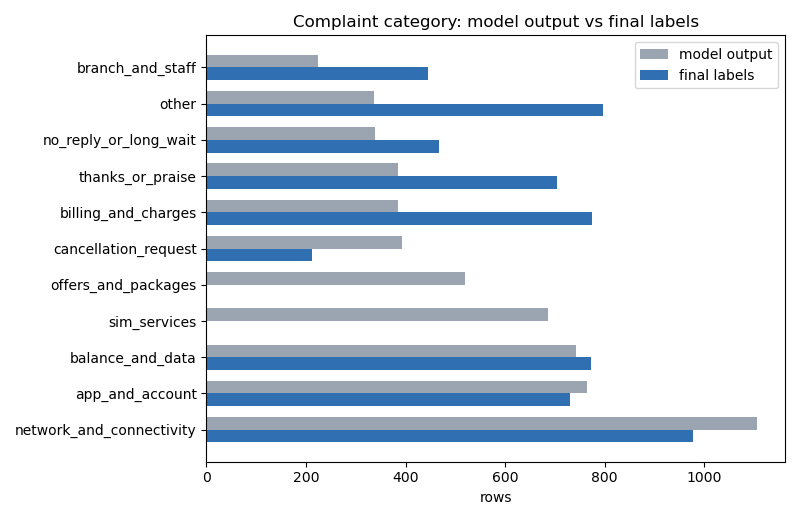

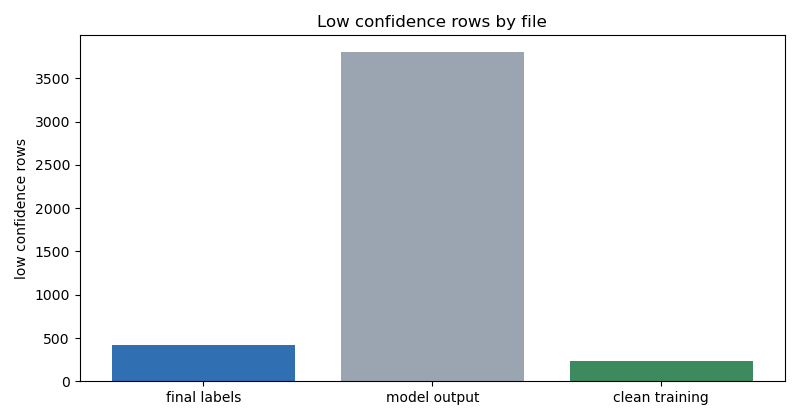

In [19]:
# Category: the model output has 11 values, the final set has 9
cats = sorted(set(mod["complaint_category"]) | set(lab["complaint_category"]))
rows = []
for c in cats:
    rows.append({"category": c,
                 "model_output": int((mod["complaint_category"] == c).sum()),
                 "final_labels": int((lab["complaint_category"] == c).sum())})
comp = pd.DataFrame(rows).sort_values("model_output", ascending=False)
print(comp.to_string(index=False))
print()
print("The model output holds sim_services (687 rows) and offers_and_packages (519 rows).")
print("The final set holds neither. Those 1,206 rows were relabeled into the 9 final categories.")
print("The largest destinations are other (285 rows), network_and_connectivity (238), and branch_and_staff (137).")
print("The final set holds other at 796 rows. The model output holds other at 337 rows.")
print()
joined = lab.set_index("file").join(mod.set_index("file"), rsuffix="_mod")
print("Agreement between the model output and the final labels, joined on file, 5,881 rows:")
for c in ["complaint_category", "complaint_urgency", "customer_state", "churn_risk"]:
    agree = int((joined[c] == joined[c + "_mod"]).sum())
    print(" ", c + ":", agree, "(" + str(round(100 * agree / len(lab), 1)) + "%)")
print()
print("Confidence:")
print(" final labels, low:", int((lab["confidence"] == "low").sum()), "| high:", int((lab["confidence"] == "high").sum()))
print(" model output, low:", int((mod["confidence"] == "low").sum()), "| high:", int((mod["confidence"] == "high").sum()))
print("The model marked 3,807 rows low confidence, 64.7 percent. The final set marks 417 rows low, 7.1 percent.")
print("The review passes resolved most of the uncertainty. They did not copy the model output.")
# Figure 1: category counts, model output vs final labels, grouped bars
fig = Figure(figsize=(8, 5.2))
ax = fig.add_subplot(111)
labels = list(comp["category"])
y = range(len(labels))
h = 0.35
ax.barh([i + h / 2 for i in y], list(comp["model_output"]), height=h, color="#9aa5b1", label="model output")
ax.barh([i - h / 2 for i in y], list(comp["final_labels"]), height=h, color="#2f6fb2", label="final labels")
ax.set_yticks(list(y))
ax.set_yticklabels(labels)
ax.set_xlabel("rows")
ax.set_title("Complaint category: model output vs final labels")
ax.legend()
fig.tight_layout()
save_fig(fig, "model_category_compare.png")
show("model_category_compare.png")
# Figure 2: low confidence rows in each file
fig2 = Figure(figsize=(8, 4.2))
ax2 = fig2.add_subplot(111)
ax2.bar(["final labels", "model output", "clean training"], [int((lab["confidence"] == "low").sum()), int((mod["confidence"] == "low").sum()), int((ct["confidence"] == "low").sum())], color=["#2f6fb2", "#9aa5b1", "#3d8a5f"])
ax2.set_ylabel("low confidence rows")
ax2.set_title("Low confidence rows by file")
fig2.tight_layout()
save_fig(fig2, "confidence_compare.png")
show("confidence_compare.png")

## 16. Five rows with no label

The audit page lists 100 rows for review. Five of them carry no model label at all: rows 95, 97, 98, 99, and 100. I find those five rows, read their transcripts, and check what happened to them. All five are quarantined rows with very low transcript confidence. None of them is in any labeled file.

audit rows: 5759
rows with no model label: 5

n 95 | audio 095.mp3 | text: سفر بصيد
   file: الكل ان شاء الله\0435.aac | logprob -1.095 | status: quarantine | quarantine decision: pending_retranscription
   reason: Pending re-transcription: 2-word fragment at very low confidence (logprob -1.10); audio may contain a real message.
n 97 | audio 097.mp3 | text: كلمة أغرب ميزة جديدة في الطبيب لإحلص مستحانة
   file: الكل ان شاء الله\WhatsApp Audio 2025-11-27 at 8.23.45 PM (1).mp4 | logprob -0.806 | status: quarantine | quarantine decision: pending_retranscription
   reason: Pending re-transcription: word salad at logprob -0.81; audio may yield a usable transcript.
n 98 | audio 098.mp3 | text: شكرا لإستقبالك
   file: الكل ان شاء الله\0892.mpeg | logprob -0.435 | status: quarantine | quarantine decision: exclude
   reason: Exclude: confident 2-word thanks, no routable content; nothing to recover.
n 99 | audio 099.mp3 | text: نشترك في صفحات المخيش أيضاً
   file: الكل ان شاء الله\WhatsApp Audio 

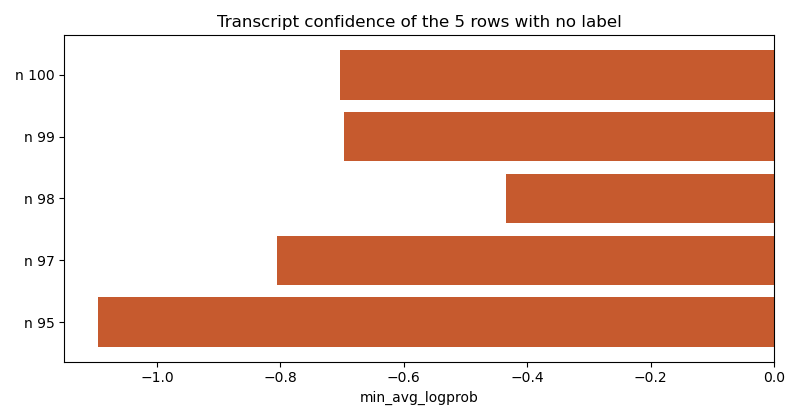

In [20]:
# The audit task list marks rows with no model label. I read the five and check each one.
nolabel = [t for t in tasks if not t.get("az")]
print("audit rows:", len(tasks))
print("rows with no model label:", len(nolabel))
print()
for t in nolabel:
    crow = clean[clean["file"] == t["file_id"]]
    qrow = quar[quar["file"] == t["file_id"]]
    lp = round(float(crow.iloc[0]["min_avg_logprob"]), 3) if len(crow) else None
    status = crow.iloc[0]["prep_status"] if len(crow) else None
    dec = qrow.iloc[0]["decision"] if len(qrow) else None
    print("n", t["n"], "| audio", t["audio"], "| text:", t["text"])
    print("   file:", t["file_id"], "| logprob", lp, "| status:", status, "| quarantine decision:", dec)
    if len(qrow):
        print("   reason:", qrow.iloc[0]["reason"])
print()
lab_files = set(lab["file"]) | set(mod["file"])
ct_files = set(ct["file"])
print("Of the 5 rows, in a labeled file:", sum(1 for t in nolabel if t["file_id"] in lab_files))
print("Of the 5 rows, in the clean training set:", sum(1 for t in nolabel if t["file_id"] in ct_files))
print("Four of the five wait on re-transcription. The re-transcription experiment showed a fresh transcription does not fix garbled audio, so these four stay out until a human listens to them.")
print("One row, n 98, is excluded: a confident two word thanks with no routable content.")
# Figure: transcript confidence of the 5 rows
fig = Figure(figsize=(8, 4.2))
ax = fig.add_subplot(111)
ns = ["n " + str(t["n"]) for t in nolabel]
lps = [round(float(clean[clean["file"] == t["file_id"]].iloc[0]["min_avg_logprob"]), 3) for t in nolabel]
ax.barh(ns, lps, color="#c65a2e")
ax.set_xlabel("min_avg_logprob")
ax.set_title("Transcript confidence of the 5 rows with no label")
fig.tight_layout()
save_fig(fig, "no_label_logprob.png")
show("no_label_logprob.png")

## 17. Does the train, validation, and test split preserve class proportions

The clean training set has 5,751 rows in three splits: train 4,023, validation 1,158, test 570. I read the three label files, compute the share of every class in every split, and compare each share with the full set share. A stratified split keeps every share close to the full set share. This one does not do that by design. The split was stratified by duration quartile and format, with whole duplicate text groups kept together, and it was made before the labels existed. The labels were never a stratification variable.

clean training rows: 5751 | train 4023 | val 1158 | test 570

complaint_category (full set shares):
  network_and_connectivity 17.1%
  billing_and_charges 13.6%
  balance_and_data 13.5%
  app_and_account 12.5%
  thanks_or_praise 12.4%
  no_reply_or_long_wait 8.2%
  branch_and_staff 7.9%
  other 6.2%
  offers_and_packages 3.8%
  cancellation_request 3.7%
  sim_services 1.1%
  largest deviation from the full set share, in points:
    train max 0.64 points (balance_and_data -0.64)
    val max 1.55 points (network_and_connectivity -1.55)
    test max 2.19 points (offers_and_packages 2.19)

complaint_urgency (full set shares):
  medium 59.7%
  low 30.7%
  high 9.7%
  largest deviation from the full set share, in points:
    train max 0.1 points (medium -0.1)
    val max 0.59 points (low 0.59)
    test max 1.39 points (medium 1.39)

customer_state (full set shares):
  frustrated 43.8%
  calm 41.0%
  satisfied 12.4%
  mad 2.8%
  unclear 0.0%
  largest deviation from the full set share, in poi

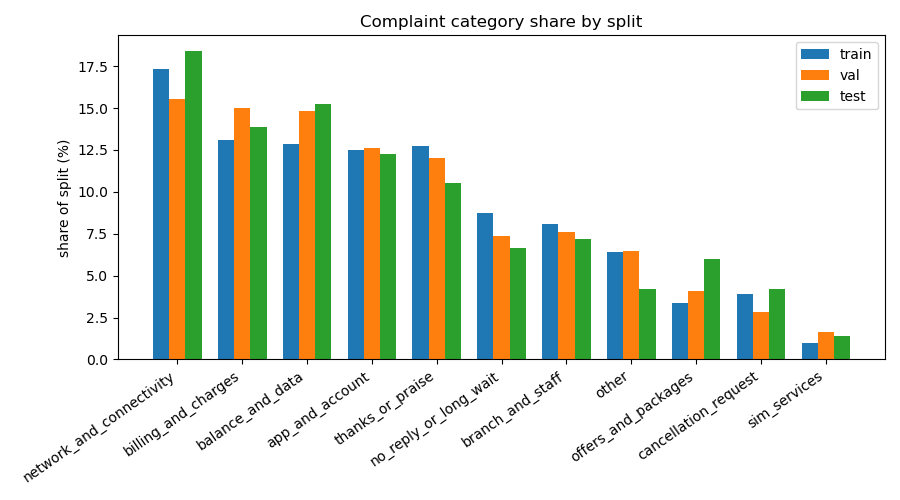

In [21]:
# Per split proportions for each label field, from the three label files
splits = {}
for s in ["train", "val", "test"]:
    splits[s] = pd.read_csv(DATASET / s / "labels.csv", encoding="utf-8-sig")
full = pd.concat([splits["train"], splits["val"], splits["test"]], ignore_index=True)
print("clean training rows:", len(full), "| train", len(splits["train"]), "| val", len(splits["val"]), "| test", len(splits["test"]))
print()
FIELDS = ["complaint_category", "complaint_urgency", "customer_state", "churn_risk"]
for f in FIELDS:
    fp = full[f].value_counts(normalize=True)
    print(f, "(full set shares):")
    for k in fp.index:
        print(" ", k, str(round(100 * fp[k], 1)) + "%")
    print("  largest deviation from the full set share, in points:")
    for s in ["train", "val", "test"]:
        p = splits[s][f].value_counts(normalize=True)
        dev = {k: round((p.get(k, 0) - fp[k]) * 100, 2) for k in fp.index}
        worst = max(dev.items(), key=lambda kv: abs(kv[1]))
        print("   ", s, "max", abs(worst[1]), "points (" + worst[0] + " " + str(worst[1]) + ")")
    print()
print("Verdict: not stratified by class.")
print("Category moves up to 2.2 points in test. A split stratified by class would hold every class within rounding, under a tenth of a point in the test split.")
print("The shares are still close, because the split is large and random inside its strata. Close by chance is not the same as controlled.")
print("This verdict is about the audio folders. The training tables use the corrected split from the preprocessing notebook.")
print()
print("Small counts in the test split (570 rows):")
print(" at_risk:", int((splits["test"]["churn_risk"] == "at_risk").sum()), "rows")
print(" sim_services:", int((splits["test"]["complaint_category"] == "sim_services").sum()), "rows")
print(" mad:", int((splits["test"]["customer_state"] == "mad").sum()), "rows")
print("Five at risk rows cannot carry a churn recall score. Eight sim_services rows cannot carry a per class score either.")
# Figure: category shares per split, grouped bars
fig = Figure(figsize=(9, 5.0))
ax = fig.add_subplot(111)
cats = list(full["complaint_category"].value_counts().index)
x = range(len(cats))
w = 0.25
for i, s in enumerate(["train", "val", "test"]):
    shares = [100 * (splits[s]["complaint_category"] == c).mean() for c in cats]
    ax.bar([j + (i - 1) * w for j in x], shares, width=w, label=s)
ax.set_xticks(list(x))
ax.set_xticklabels(cats, rotation=35, ha="right")
ax.set_ylabel("share of split (%)")
ax.set_title("Complaint category share by split")
ax.legend()
fig.tight_layout()
save_fig(fig, "split_category.png")
show("split_category.png")

## 18. What the class analysis adds

1. Category is a long tail. Network holds 978 rows and cancellation holds 212, a 4.6 to 1 spread, and other at 796 rows is a bucket, not a topic. The clean set narrows other to 357 rows and adds offers and sim, but sim_services at 66 rows is the smallest class in training.
2. Urgency is dominated by medium at 57.7 percent. High is 9.2 percent, 542 rows, enough to learn from and small enough to need weighting.
3. State is dominated by frustrated at 42.2 percent and calm at 39.7 percent. Mad is 2.7 percent, 160 rows. The model output disagrees most here: it calls 4,111 rows frustrated where the final labels call 2,480 frustrated.
4. Churn is the extreme case: 32 at risk rows out of 5,881, and 5 in the test split. No test set that small can measure churn recall.
5. The model output and the final labels agree on category in only 40.4 percent of rows. The final labels are the reviewed result, not the model output.
6. Confidence is the gap between the two files. The model marked 3,807 rows low confidence. The final set marks 417 low. The review passes resolved most of the uncertainty.
7. Five audit rows have no label at all. They are quarantined, low confidence, and four of them wait on re-transcription that the experiment showed does not help garbled audio. They stay out of training.
8. The split is not stratified by class. It was stratified by duration and format before the labels existed. The shares are close but not controlled, and the test split is the loosest. The preprocessing notebook builds a corrected split.

In [22]:
# Class balance at a glance, after the analysis and before the fixes
print("CLASS BALANCE AT A GLANCE (after the analysis, before the fixes)")
print("labeled rows:", len(lab), "| clean training rows:", len(ct))
print("category: largest network_and_connectivity", int((lab["complaint_category"] == "network_and_connectivity").sum()), "| smallest cancellation_request", int((lab["complaint_category"] == "cancellation_request").sum()))
print("urgency high:", int((lab["complaint_urgency"] == "high").sum()), "| state mad:", int((lab["customer_state"] == "mad").sum()), "| churn at_risk:", int((lab["churn_risk"] == "at_risk").sum()))
print("test split: at_risk", int((splits["test"]["churn_risk"] == "at_risk").sum()), "| sim_services", int((splits["test"]["complaint_category"] == "sim_services").sum()), "| mad", int((splits["test"]["customer_state"] == "mad").sum()))
print("low confidence rows: labeled set", int((lab["confidence"] == "low").sum()), "| model output", int((mod["confidence"] == "low").sum()), "| clean training", int((ct["confidence"] == "low").sum()))
print("rows with no label: 5 (audit rows 95, 97, 98, 99, 100)")
print("split stratified by class: no (stratified by duration quartile and format)")

CLASS BALANCE AT A GLANCE (after the analysis, before the fixes)
labeled rows: 5881 | clean training rows: 5751
category: largest network_and_connectivity 978 | smallest cancellation_request 212
urgency high: 542 | state mad: 160 | churn at_risk: 32
test split: at_risk 5 | sim_services 8 | mad 24
low confidence rows: labeled set 417 | model output 3807 | clean training 240
rows with no label: 5 (audit rows 95, 97, 98, 99, 100)
split stratified by class: no (stratified by duration quartile and format)
